<a href="https://colab.research.google.com/github/ercanaksakal/turkce-mini-gpt/blob/main/adim1_pytorch_isinma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adım 1 — PyTorch Isınma
Kendi yapay zekâmızın ilk taşı. Bu defterde:
1. GPU'yu açıp kontrol edeceğiz
2. Google Drive'ı bağlayıp kayıt klasörü kuracağız (PC'ye geçişte buradan devam edeceğiz)
3. Tensörleri ve otomatik türevi (autograd) öğreneceğiz
4. İlk modelimizi eğiteceğiz (doğru denklemi bulma)
5. Gerçek bir sinir ağıyla el yazısı rakam tanıyacağız (MNIST)
6. Modeli kaydedip geri yükleyeceğiz

**Başlamadan önce:** Menüden `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU` seç.

## 1. GPU kontrolü

In [2]:
import torch
print("PyTorch sürümü:", torch.__version__)

# Cihazdan bağımsız kod: Colab'da GPU, kendi PC'nde de GPU, yoksa CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Kullanılan cihaz:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch sürümü: 2.11.0+cu130
Kullanılan cihaz: cuda
GPU: Tesla T4


## 2. Google Drive bağlantısı
Eğittiğimiz modelleri buraya kaydedeceğiz. Colab oturumu kapansa da kaybolmaz; PC'ye de buradan indiririz.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
KAYIT_KLASORU = "/content/drive/MyDrive/yapay_zeka_projesi/checkpoints"
os.makedirs(KAYIT_KLASORU, exist_ok=True)
print("Kayıt klasörü hazır:", KAYIT_KLASORU)

Mounted at /content/drive
Kayıt klasörü hazır: /content/drive/MyDrive/yapay_zeka_projesi/checkpoints


## 3. Tensörler
Tensör = çok boyutlu sayı dizisi. Yapay zekâdaki her şey (metin, resim, modelin ağırlıkları) tensördür.

In [4]:
a = torch.tensor([1.0, 2.0, 3.0])          # 1 boyutlu (vektör)
b = torch.tensor([[1, 2], [3, 4]])          # 2 boyutlu (matris)
c = torch.randn(2, 3)                       # rastgele sayılarla 2x3

print("a:", a, "şekil:", a.shape)
print("b:\n", b, "şekil:", b.shape)
print("c:\n", c)

# İşlemler
print("a * 2 =", a * 2)
print("a + a =", a + a)
print("b @ b (matris çarpımı) =\n", b @ b)

# GPU'ya taşıma — büyük hesaplar burada çok daha hızlı
c_gpu = c.to(device)
print("c şu an nerede:", c_gpu.device)

a: tensor([1., 2., 3.]) şekil: torch.Size([3])
b:
 tensor([[1, 2],
        [3, 4]]) şekil: torch.Size([2, 2])
c:
 tensor([[ 0.8639,  0.2888, -0.3150],
        [ 0.6564, -0.4941,  0.2808]])
a * 2 = tensor([2., 4., 6.])
a + a = tensor([2., 4., 6.])
b @ b (matris çarpımı) =
 tensor([[ 7, 10],
        [15, 22]])
c şu an nerede: cuda:0


## 4. Otomatik türev (autograd)
Sinir ağlarının öğrenmesinin sırrı: PyTorch, hatanın her ağırlığa göre türevini kendisi hesaplar.
Örnek: y = x² ise, x=3 noktasında türev 2·3 = 6 olmalı.

In [5]:
x = torch.tensor(3.0, requires_grad=True)   # "bu sayının türevini takip et"
y = x ** 2
y.backward()                                # türevi hesapla
print("dy/dx =", x.grad)                    # 6.0 çıkmalı

dy/dx = tensor(6.)


## 5. İlk model: gizli denklemi bulma
Gerçek kural **y = 3x + 2**. Modele bunu söylemiyoruz; sadece örnek veriyoruz.
Model 3 ve 2 sayılarını kendisi bulmaya çalışacak. Bu, tüm yapay zekâ eğitiminin özüdür:
**tahmin et → hatayı ölç → ağırlıkları düzelt → tekrarla.**

In [6]:
import torch.nn as nn

# Veri: 100 örnek, biraz gürültülü
X = torch.rand(100, 1) * 10
Y = 3 * X + 2 + torch.randn(100, 1) * 0.5
X, Y = X.to(device), Y.to(device)

model = nn.Linear(1, 1).to(device)          # tek ağırlık + tek sabit
kayip_fonk = nn.MSELoss()                   # hata ölçüsü
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

for adim in range(1000):
    tahmin = model(X)                       # 1) tahmin et
    kayip = kayip_fonk(tahmin, Y)           # 2) hatayı ölç
    optimizer.zero_grad()
    kayip.backward()                        # 3) türevleri hesapla
    optimizer.step()                        # 4) ağırlıkları düzelt
    if adim % 200 == 0:
        print(f"Adım {adim:4d} | hata: {kayip.item():.4f}")

print("\nModelin bulduğu eğim  :", round(model.weight.item(), 3), "(gerçek: 3)")
print("Modelin bulduğu sabit :", round(model.bias.item(), 3), "(gerçek: 2)")

Adım    0 | hata: 625.3182
Adım  200 | hata: 0.2860
Adım  400 | hata: 0.2347
Adım  600 | hata: 0.2261
Adım  800 | hata: 0.2246

Modelin bulduğu eğim  : 2.995 (gerçek: 3)
Modelin bulduğu sabit : 2.017 (gerçek: 2)


## 6. Gerçek sinir ağı: el yazısı rakam tanıma (MNIST)
70.000 adet 28x28 piksellik el yazısı rakam. Ağımız resme bakıp 0–9 arası hangi rakam olduğunu söyleyecek.

In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

donusum = transforms.ToTensor()
egitim_veri = datasets.MNIST(root="data", train=True, download=True, transform=donusum)
test_veri   = datasets.MNIST(root="data", train=False, download=True, transform=donusum)

egitim_yukleyici = DataLoader(egitim_veri, batch_size=64, shuffle=True)
test_yukleyici   = DataLoader(test_veri, batch_size=256)

print("Eğitim örneği:", len(egitim_veri), "| Test örneği:", len(test_veri))

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.95MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.07MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.94MB/s]

Eğitim örneği: 60000 | Test örneği: 10000


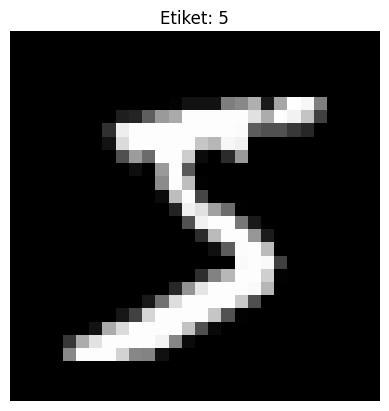

In [8]:
# Bir örneğe bakalım
import matplotlib.pyplot as plt
resim, etiket = egitim_veri[0]
plt.imshow(resim.squeeze(), cmap="gray")
plt.title(f"Etiket: {etiket}")
plt.axis("off")
plt.show()

In [9]:
class RakamAgi(nn.Module):
    def __init__(self, gizli=128):
        super().__init__()
        self.katmanlar = nn.Sequential(
            nn.Flatten(),               # 28x28 resmi 784 sayılık satıra çevir
            nn.Linear(784, gizli),      # 1. katman
            nn.ReLU(),                  # doğrusal olmayan dönüşüm
            nn.Linear(gizli, gizli),
            nn.ReLU(),
            nn.Linear(gizli, 10),       # çıkış: 10 rakam için puan
        )
    def forward(self, x):
        return self.katmanlar(x)

ag = RakamAgi().to(device)
print(ag)
print("Toplam parametre:", sum(p.numel() for p in ag.parameters()))

RakamAgi(
  (katmanlar): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Toplam parametre: 118282


In [10]:
kayip_fonk = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(ag.parameters(), lr=1e-3)

def dogruluk_olc(model):
    model.eval()
    dogru = 0
    with torch.no_grad():
        for x, y in test_yukleyici:
            x, y = x.to(device), y.to(device)
            dogru += (model(x).argmax(1) == y).sum().item()
    model.train()
    return dogru / len(test_veri)

for donem in range(3):                       # 3 tur (epoch)
    for x, y in egitim_yukleyici:
        x, y = x.to(device), y.to(device)
        kayip = kayip_fonk(ag(x), y)
        optimizer.zero_grad()
        kayip.backward()
        optimizer.step()
    print(f"Tur {donem+1} | son hata: {kayip.item():.4f} | test doğruluğu: %{dogruluk_olc(ag)*100:.2f}")

Tur 1 | son hata: 0.5060 | test doğruluğu: %95.25
Tur 2 | son hata: 0.0193 | test doğruluğu: %96.62
Tur 3 | son hata: 0.0142 | test doğruluğu: %97.11


## 7. Kaydet ve geri yükle (checkpoint)
Bu dosyayı ileride kendi PC'nde aynen açabileceksin.

In [11]:
dosya = f"{KAYIT_KLASORU}/rakam_agi.pt"
torch.save({"model": ag.state_dict(), "optimizer": optimizer.state_dict()}, dosya)
print("Kaydedildi:", dosya)

# Sıfırdan yeni ağ oluşturup kaydı yükleyelim
yeni_ag = RakamAgi().to(device)
kayit = torch.load(dosya, map_location=device)   # map_location: GPU'suz bilgisayarda da açılır
yeni_ag.load_state_dict(kayit["model"])
print("Yüklenen modelin doğruluğu: %", round(dogruluk_olc(yeni_ag)*100, 2))

Kaydedildi: /content/drive/MyDrive/yapay_zeka_projesi/checkpoints/rakam_agi.pt
Yüklenen modelin doğruluğu: % 97.11


## 8. Alıştırmalar
1. `RakamAgi(gizli=128)` yerine `gizli=32` ve `gizli=512` dene. Doğruluk ve parametre sayısı nasıl değişiyor?
2. Ağa ikinci bir gizli katman ekle (`nn.Linear(gizli, gizli)` + `nn.ReLU()`).
3. 5. bölümde `lr=0.01` yerine `lr=0.1` ve `lr=0.0001` dene. Ne oluyor, neden?
4. Bonus: Test setinden rastgele bir resim seç, ekrana çiz ve modelin tahminini başlığa yaz.

Sonuçlarını not al; bir sonraki adımda (mini Türkçe dil modeli) bu deneyim doğrudan işine yarayacak.